In [10]:
import random
import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import xgi


# Random q-uniform hypergraph using xgi
def generate_random_hypergraph_xgi(n, q, p):
    H = xgi.uniform_erdos_renyi_hypergraph(
        n,
        q,
        p,
        p_type="prob"
    )
    V = list(H.nodes)
    E = [set(e) for e in H.edges.members()]
    return V, E


# Greedy independent set
def greedy_independent_set(V, E):
    I = set()

    for v in V:
        conflict = False
        for e in E:
            if v in e and e.issubset(I | {v}):
                conflict = True
                break
        if not conflict:
            I.add(v)

    return I


# Degree computation (for Algorithm 1)
def compute_degrees(container, edges):
    deg = defaultdict(int)

    for e in edges:
        if e.issubset(container):
            for v in e:
                deg[v] += 1

    return deg


# Algorithm 1 (nested loops)
def algorithm1(V, E, I, q, rho):
    C = set(V)
    F = []
    n = len(V)
    t = 0

    while len(C) > rho * n and I & C:
        t += 1

        D_vertices = C.copy()
        D_edges = [e.copy() for e in E if e.issubset(C)]

        X_sets = []
        fingerprint_round = []

        for ell in range(q, 1, -1):

            deg = compute_degrees(D_vertices, D_edges)
            candidates = (I - set(v for block in F for v in block)) & D_vertices

            if not candidates:
                break

            v = max(candidates, key=lambda x: deg[x])
            fingerprint_round.append(v)

            X_ell = {w for w in D_vertices if deg[w] > deg[v]}
            X_sets.append(X_ell)

            # shrink edges containing v
            D_edges = [e - {v} for e in D_edges if v in e]
            D_vertices.remove(v)

        F.append(fingerprint_round)

        # Update container
        for X in X_sets:
            C -= X

        C -= set(fingerprint_round)

        # remove 1-edges
        one_edges = {next(iter(e)) for e in D_edges if len(e) == 1}
        C -= one_edges

    return t, len(C)


# Normalized degree for Algorithm 2
def normalized_degrees(F, C, E, n, q):
    deg = defaultdict(int)

    for e in E:
        if e.issubset(C | F):
            intersection_size = len(e & F)
            weight = n ** intersection_size

            for v in e:
                if v not in F:
                    deg[v] += weight

    return deg


# Algorithm 2 (normalized degree version)
def algorithm2(V, E, I, q, rho):

    C = set(V)
    F = []
    F_set = set()
    n = len(V)
    t = 0

    while len(C) > rho * n and (I & C):
        
        t += 1
        candidates = list(I - F_set)

        deg = normalized_degrees(F_set, C, E, n, q)

        v = max(candidates, key=lambda x: deg.get(x, 0))
        v_deg = deg.get(v, 0)

        # Remove higher normalized degree vertices
        remove_high = {w for w in C if deg.get(w, 0) > v_deg}
        C -= remove_high

        F.append(v)
        F_set.add(v)
        C.discard(v)

        # Remove singleton neighbors
        remove_singletons = set()
        for e in E:
            if len(e & F_set) == q - 1:
                remaining = next(iter(e - F_set))
                if remaining in C:
                    remove_singletons.add(remaining)

        C -= remove_singletons

    return t, len(C)

In [32]:
# Simulation 
def run_simulation(n_values, p_values, q=3, rho=0.05, trials=10): 
    results = {} 
    for n in n_values: 
        for p in p_values: 
            algo1_steps = [] 
            algo2_steps = [] 
            
            for _ in range(trials): 
                V, E = generate_random_hypergraph_xgi(n, q, p) 
                I = greedy_independent_set(V, E) 
                t1, _ = algorithm1(V, E, I, q, rho) 
                t2, _ = algorithm2(V, E, I, q, rho) 
                algo1_steps.append(t1) 
                algo2_steps.append(t2) 
                
            results[(n, p)] = ( np.mean(algo1_steps), np.mean(algo2_steps) ) 
            print(f"n={n}, p={p}: Algo1={np.mean(algo1_steps):.2f}, Algo2={np.mean(algo2_steps):.2f}") 
    return results 
                
# Plot 
def plot_results(results, n_values, q, p_fixed): 
    algo1 = [] 
    algo2 = [] 
    for n in n_values: 
        a1, a2 = results[(n, p_fixed)] 
        algo1.append(a1) 
        algo2.append(a2) 
    plt.figure() 
    plt.plot(n_values, [val*(q-1) for val in algo1], label="Algo 1") 
    plt.plot(n_values, algo2, label="Algo 2") 
    plt.xlabel("n") 
    plt.ylabel("Average Steps to Reach ρn") 
    plt.title(f"Convergence Comparison (p={p_fixed})") 
    plt.legend() 
    plt.show() 

n=50, p=0.1: Algo1=4.50, Algo2=7.00
n=50, p=0.15000000000000002: Algo1=4.10, Algo2=6.00
n=50, p=0.2: Algo1=3.70, Algo2=5.30
n=50, p=0.25: Algo1=3.00, Algo2=4.80
n=90, p=0.1: Algo1=5.20, Algo2=7.30
n=90, p=0.15000000000000002: Algo1=4.20, Algo2=5.90
n=90, p=0.2: Algo1=3.60, Algo2=5.20
n=90, p=0.25: Algo1=3.30, Algo2=4.80
n=120, p=0.1: Algo1=5.10, Algo2=6.90
n=120, p=0.15000000000000002: Algo1=4.40, Algo2=5.90
n=120, p=0.2: Algo1=4.00, Algo2=5.00
n=120, p=0.25: Algo1=3.60, Algo2=4.70
n=140, p=0.1: Algo1=5.00, Algo2=6.80
n=140, p=0.15000000000000002: Algo1=4.70, Algo2=6.00
n=140, p=0.2: Algo1=4.00, Algo2=5.10
n=140, p=0.25: Algo1=3.70, Algo2=4.80


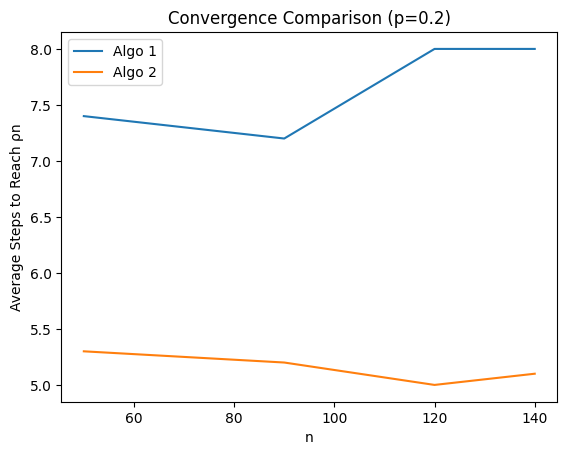

In [33]:
# Main 
if __name__ == "__main__": 
    n_values = [50,90,120,140] 
    p_values = [0.05 + 0.05 * x for x in range(1, 5, 1)] 
    q = 3 
    rho = 0.05 
    trials = 10 
    results = run_simulation(n_values, p_values, q=q, rho=rho, trials=trials) 
    plot_results(results, n_values, q, p_fixed=0.2)

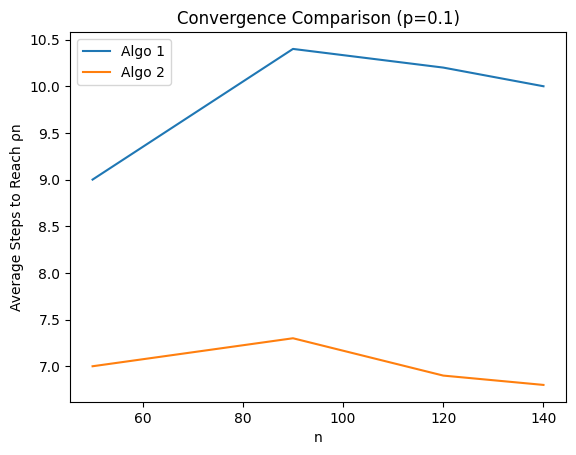

In [34]:
plot_results(results, n_values, q, p_fixed=0.1)

In [6]:
# Random q-uniform hypergraph using xgi
def generate_random_hypergraph_xgi(n, q, p):
    H = xgi.uniform_erdos_renyi_hypergraph(
        n,
        q,
        int(p * math.comb(n,q) / n),
        p_type="degree"
    )
    V = list(H.nodes)
    E = [set(e) for e in H.edges.members()]
    return V, E

In [35]:
n_values2 = [50,90,140,200] 
p_values2 = [0.01 + 0.01 * x for x in range(1, 7, 1)] 
q2 = 3 
rho2 = 0.05 
trials2 = 10 
results2 = run_simulation(n_values2, p_values2, q=q2, rho=rho2, trials=trials2)

n=50, p=0.02: Algo1=8.40, Algo2=14.40
n=50, p=0.03: Algo1=7.10, Algo2=12.00
n=50, p=0.04: Algo1=6.70, Algo2=10.90
n=50, p=0.05: Algo1=5.80, Algo2=9.50
n=50, p=0.060000000000000005: Algo1=5.70, Algo2=9.30
n=50, p=0.06999999999999999: Algo1=5.60, Algo2=8.60
n=90, p=0.02: Algo1=9.70, Algo2=14.90
n=90, p=0.03: Algo1=8.50, Algo2=12.60
n=90, p=0.04: Algo1=7.00, Algo2=10.40
n=90, p=0.05: Algo1=6.80, Algo2=9.50
n=90, p=0.060000000000000005: Algo1=6.30, Algo2=8.80
n=90, p=0.06999999999999999: Algo1=6.00, Algo2=8.10
n=140, p=0.02: Algo1=10.50, Algo2=14.40
n=140, p=0.03: Algo1=8.60, Algo2=11.50
n=140, p=0.04: Algo1=7.80, Algo2=10.20
n=140, p=0.05: Algo1=7.10, Algo2=9.20
n=140, p=0.060000000000000005: Algo1=6.30, Algo2=8.40
n=140, p=0.06999999999999999: Algo1=6.40, Algo2=7.90
n=200, p=0.02: Algo1=10.60, Algo2=13.80
n=200, p=0.03: Algo1=8.90, Algo2=11.50
n=200, p=0.04: Algo1=7.90, Algo2=10.00
n=200, p=0.05: Algo1=7.30, Algo2=9.40
n=200, p=0.060000000000000005: Algo1=6.90, Algo2=8.40
n=200, p=0.0699

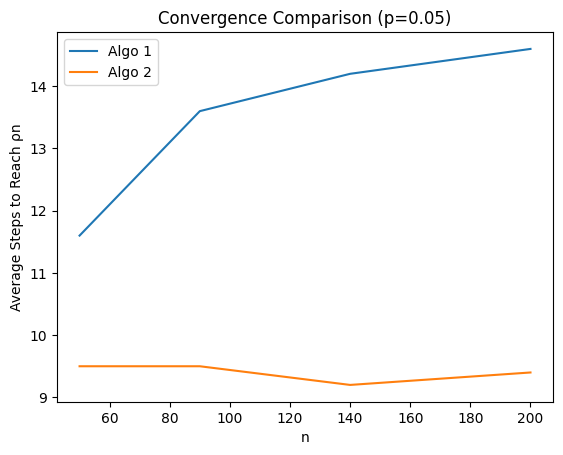

In [36]:
plot_results(results2, n_values2, q2, 0.05)

In [37]:
n_values3 = range(20,100,10)
p_values3 = [0.005 + 0.005 * x for x in range(1, 10, 1)] 
q3 = 4 
rho3 = 0.05 
trials3 = 10 
results3 = run_simulation(n_values3, p_values3, q=q3, rho=rho3, trials=trials3)

n=20, p=0.01: Algo1=4.10, Algo2=10.40
n=20, p=0.015: Algo1=3.90, Algo2=9.50
n=20, p=0.02: Algo1=3.70, Algo2=9.10
n=20, p=0.025: Algo1=3.40, Algo2=8.30
n=20, p=0.030000000000000002: Algo1=3.30, Algo2=8.20
n=20, p=0.034999999999999996: Algo1=3.20, Algo2=8.10
n=20, p=0.04: Algo1=3.10, Algo2=7.70
n=20, p=0.045: Algo1=3.00, Algo2=7.40
n=20, p=0.049999999999999996: Algo1=3.00, Algo2=7.30
n=30, p=0.01: Algo1=4.60, Algo2=11.60
n=30, p=0.015: Algo1=4.00, Algo2=10.00
n=30, p=0.02: Algo1=4.00, Algo2=9.70
n=30, p=0.025: Algo1=3.90, Algo2=9.20
n=30, p=0.030000000000000002: Algo1=3.80, Algo2=9.20
n=30, p=0.034999999999999996: Algo1=3.60, Algo2=8.50
n=30, p=0.04: Algo1=3.10, Algo2=7.90
n=30, p=0.045: Algo1=3.00, Algo2=7.50
n=30, p=0.049999999999999996: Algo1=3.00, Algo2=7.60
n=40, p=0.01: Algo1=4.90, Algo2=11.20
n=40, p=0.015: Algo1=4.20, Algo2=10.10
n=40, p=0.02: Algo1=4.20, Algo2=9.80
n=40, p=0.025: Algo1=3.90, Algo2=8.80
n=40, p=0.030000000000000002: Algo1=3.80, Algo2=8.50
n=40, p=0.03499999999999

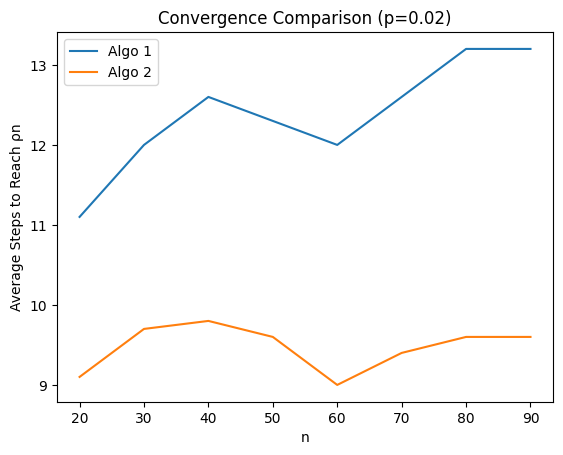

In [38]:
plot_results(results3, n_values3, q3, 0.02)

In [1]:
# Normalized degree for Algorithm 2
def normalized_degrees2(F, C, E, n, q):
    deg = defaultdict(int)

    for e in E:
        if e.issubset(C | F):
            intersection_size = len(e & F)
            weight = 1

            for v in e:
                if v not in F:
                    deg[v] += weight

    return deg

In [2]:
# Algorithm 2 (normalized degree version)
def algorithm3(V, E, I, q, rho):

    C = set(V)
    F = []
    F_set = set()
    n = len(V)
    t = 0

    while len(C) > rho * n and (I & C):
        
        t += 1
        candidates = list(I - F_set)

        deg = normalized_degrees2(F_set, C, E, n, q)

        v = max(candidates, key=lambda x: deg.get(x, 0))
        v_deg = deg.get(v, 0)

        # Remove higher normalized degree vertices
        remove_high = {w for w in C if deg.get(w, 0) > v_deg}
        C -= remove_high

        F.append(v)
        F_set.add(v)
        C.discard(v)

        # Remove singleton neighbors
        remove_singletons = set()
        for e in E:
            if len(e & F_set) == q - 1:
                remaining = next(iter(e - F_set))
                if remaining in C:
                    remove_singletons.add(remaining)

        C -= remove_singletons

    return t, len(C)

In [14]:
# Simulation 
def run_simulation(n_values, p_values, q=3, rho=0.05, trials=10): 
    results = {} 
    for n in n_values: 
        for p in p_values: 
            algo1_steps = [] 
            algo2_steps = [] 
            algo3_steps = []
            
            for _ in range(trials): 
                V, E = generate_random_hypergraph_xgi(n, q, p) 
                I = greedy_independent_set(V, E) 
                t1, _ = algorithm1(V, E, I, q, rho) 
                t2, _ = algorithm2(V, E, I, q, rho) 
                t3, _ = algorithm3(V, E, I, q, rho) 
                algo1_steps.append(t1) 
                algo2_steps.append(t2) 
                algo3_steps.append(t3) 
                
            results[(n, p)] = ( np.mean(algo1_steps), np.mean(algo2_steps), np.mean(algo3_steps) ) 
            print(f"n={n}, p={p}: Algo1={np.mean(algo1_steps):.2f}, Algo2={np.mean(algo2_steps):.2f}, Algo3={np.mean(algo3_steps):.2f}") 
    return results 
                
# Plot 
def plot_results(results, n_values, q, p_fixed): 
    algo1 = [] 
    algo2 = [] 
    algo3 = []
    for n in n_values: 
        a1, a2, a3 = results[(n, p_fixed)] 
        algo1.append(a1) 
        algo2.append(a2) 
        algo3.append(a3) 
    plt.figure() 
    plt.plot(n_values, [val*(q-1) for val in algo1], label="Algo 1") 
    plt.plot(n_values, algo2, label="Algo 2") 
    plt.plot(n_values, algo3, label="Algo 3") 
    plt.xlabel("n") 
    plt.ylabel("Average Steps to Reach ρn") 
    plt.title(f"Convergence Comparison (p={p_fixed})") 
    plt.legend() 
    plt.show() 

n=50, p=0.1: Algo1=4.70, Algo2=7.30, Algo3=7.40
n=50, p=0.15000000000000002: Algo1=3.90, Algo2=5.90, Algo3=6.20
n=50, p=0.2: Algo1=3.50, Algo2=5.20, Algo3=5.40
n=50, p=0.25: Algo1=3.10, Algo2=4.80, Algo3=5.00
n=90, p=0.1: Algo1=4.90, Algo2=7.00, Algo3=7.10
n=90, p=0.15000000000000002: Algo1=4.30, Algo2=5.90, Algo3=6.10
n=90, p=0.2: Algo1=4.00, Algo2=5.10, Algo3=5.10
n=90, p=0.25: Algo1=3.40, Algo2=4.90, Algo3=5.00
n=120, p=0.1: Algo1=5.10, Algo2=7.10, Algo3=7.10
n=120, p=0.15000000000000002: Algo1=4.40, Algo2=5.80, Algo3=6.20
n=120, p=0.2: Algo1=4.00, Algo2=5.00, Algo3=5.50
n=120, p=0.25: Algo1=3.40, Algo2=4.60, Algo3=4.90
n=140, p=0.1: Algo1=5.30, Algo2=7.00, Algo3=7.10
n=140, p=0.15000000000000002: Algo1=4.70, Algo2=5.80, Algo3=6.20
n=140, p=0.2: Algo1=3.90, Algo2=5.10, Algo3=5.60
n=140, p=0.25: Algo1=3.40, Algo2=4.90, Algo3=4.80


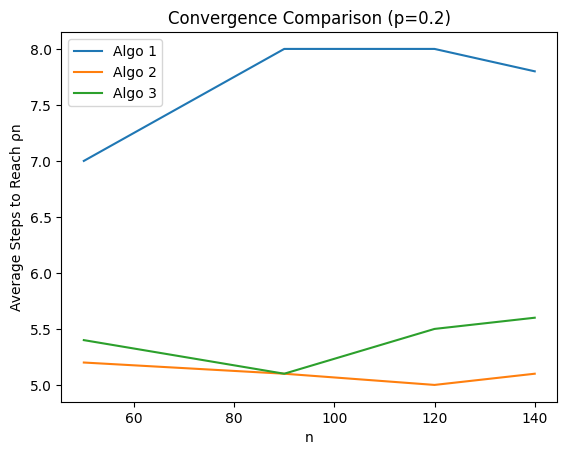

In [16]:
# Main 
if __name__ == "__main__": 
    n_values = [50,90,120,140] 
    p_values = [0.05 + 0.05 * x for x in range(1, 5, 1)] 
    q = 3 
    rho = 0.05 
    trials = 10 
    results = run_simulation(n_values, p_values, q=q, rho=rho, trials=trials) 
    plot_results(results, n_values, q, p_fixed=0.2)

In [17]:
n_values2 = [50,90,140,200] 
p_values2 = [0.01 + 0.01 * x for x in range(1, 7, 1)] 
q2 = 3 
rho2 = 0.05 
trials2 = 10 
results2 = run_simulation(n_values2, p_values2, q=q2, rho=rho2, trials=trials2)

n=50, p=0.02: Algo1=8.30, Algo2=14.10, Algo3=14.20
n=50, p=0.03: Algo1=7.40, Algo2=12.30, Algo3=12.30
n=50, p=0.04: Algo1=6.90, Algo2=11.40, Algo3=11.40
n=50, p=0.05: Algo1=6.10, Algo2=9.80, Algo3=9.90
n=50, p=0.060000000000000005: Algo1=5.60, Algo2=9.00, Algo3=8.90
n=50, p=0.06999999999999999: Algo1=5.10, Algo2=8.20, Algo3=8.30
n=90, p=0.02: Algo1=9.80, Algo2=14.80, Algo3=15.10
n=90, p=0.03: Algo1=8.20, Algo2=12.20, Algo3=12.40
n=90, p=0.04: Algo1=7.30, Algo2=10.50, Algo3=10.70
n=90, p=0.05: Algo1=6.50, Algo2=9.20, Algo3=9.50
n=90, p=0.060000000000000005: Algo1=6.30, Algo2=8.70, Algo3=9.10
n=90, p=0.06999999999999999: Algo1=5.90, Algo2=8.00, Algo3=8.10
n=140, p=0.02: Algo1=10.50, Algo2=14.20, Algo3=14.80
n=140, p=0.03: Algo1=8.60, Algo2=11.40, Algo3=11.50
n=140, p=0.04: Algo1=7.70, Algo2=10.10, Algo3=10.60
n=140, p=0.05: Algo1=6.90, Algo2=9.00, Algo3=9.10
n=140, p=0.060000000000000005: Algo1=6.50, Algo2=8.50, Algo3=8.90
n=140, p=0.06999999999999999: Algo1=6.30, Algo2=7.70, Algo3=8.30


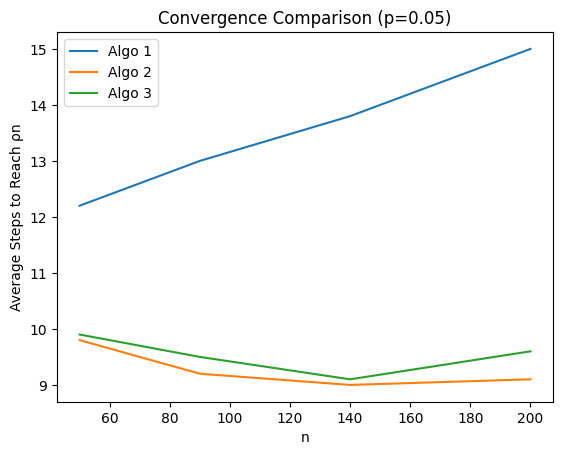

In [18]:
plot_results(results2, n_values2, q2, 0.05)

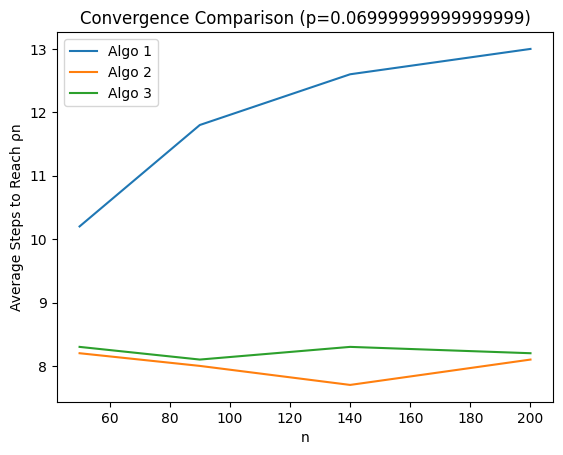

In [19]:
plot_results(results2, n_values2, q2, 0.06999999999999999)

In [20]:
n_values3 = range(20,100,10)
p_values3 = [0.005 + 0.005 * x for x in range(1, 20, 1)] 
q3 = 4 
rho3 = 0.05 
trials3 = 10 
results3 = run_simulation(n_values3, p_values3, q=q3, rho=rho3, trials=trials3)

n=20, p=0.01: Algo1=4.30, Algo2=11.00, Algo3=11.00
n=20, p=0.015: Algo1=3.80, Algo2=9.20, Algo3=9.20
n=20, p=0.02: Algo1=3.90, Algo2=9.40, Algo3=9.40
n=20, p=0.025: Algo1=3.40, Algo2=8.40, Algo3=8.40
n=20, p=0.030000000000000002: Algo1=3.10, Algo2=8.10, Algo3=8.10
n=20, p=0.034999999999999996: Algo1=3.60, Algo2=8.60, Algo3=8.60
n=20, p=0.04: Algo1=3.00, Algo2=7.60, Algo3=7.70
n=20, p=0.045: Algo1=3.00, Algo2=7.10, Algo3=7.40
n=20, p=0.049999999999999996: Algo1=3.00, Algo2=7.30, Algo3=7.20
n=20, p=0.055: Algo1=3.10, Algo2=7.00, Algo3=6.90
n=20, p=0.06: Algo1=2.90, Algo2=6.70, Algo3=6.70
n=20, p=0.065: Algo1=3.00, Algo2=6.80, Algo3=6.90
n=20, p=0.07: Algo1=2.90, Algo2=6.50, Algo3=6.60
n=20, p=0.07500000000000001: Algo1=2.90, Algo2=6.50, Algo3=6.60
n=20, p=0.08: Algo1=3.00, Algo2=6.60, Algo3=6.70
n=20, p=0.085: Algo1=2.90, Algo2=6.60, Algo3=6.60
n=20, p=0.09000000000000001: Algo1=2.50, Algo2=6.00, Algo3=6.00
n=20, p=0.095: Algo1=2.80, Algo2=6.00, Algo3=6.10
n=20, p=0.1: Algo1=2.80, Algo2=

In [ ]:
plot_results(results3, n_values3, q3, 0.02)

In [ ]:
plot_results(results3, n_values3, q3, 0.055)

In [ ]:
plot_results(results3, n_values3, q3, 0.08)